### 🧠 Answer Synthesis from Multiple Sources (Groq + HuggingFace)
1. **Query transformer**: turns the question into search-friendly keywords
2. **Parallel retrieval** from 4 sources: Internal docs, YouTube (mock), Wikipedia, ArXiv
3. Each source is size-limited and failure-safe
4. **Synthesizer** merges everything, **cites sources**, ignores irrelevant ones,
   and keeps internal notes separate from public research

In [12]:
import os
from dotenv import load_dotenv, find_dotenv

# .env sits in the repo root, one level above this notebook
load_dotenv(find_dotenv(usecwd=True), override=True)

# .env stores the keys in lowercase; ChatGroq and huggingface_hub read the uppercase names
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY") or os.getenv("groq_api", "")
os.environ["HF_TOKEN"] = os.getenv("HF_TOKEN") or os.getenv("hf_token", "")
assert os.environ["GROQ_API_KEY"], "groq_api / GROQ_API_KEY missing in .env"

# Removes the WebBaseLoader warning (must be set before langchain_community is imported)
os.environ.setdefault("USER_AGENT", "rag-learning-notebook/1.0")
print("GROQ_API_KEY loaded:", os.environ["GROQ_API_KEY"].startswith("gsk_"))

GROQ_API_KEY loaded: True


In [13]:
from typing import List
from pydantic import BaseModel, Field

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper

from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import StateGraph, END

In [14]:
GROQ_MODEL = "openai/gpt-oss-20b"   # no "groq:" prefix with ChatGroq

llm = ChatGroq(model=GROQ_MODEL, temperature=0)

# One embeddings object, reused for every vector store
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [15]:
MAX_CHARS_PER_SOURCE = 2500   # keeps us under Groq free-tier token limits

def _truncate(text: str, limit: int = MAX_CHARS_PER_SOURCE) -> str:
    return text if len(text) <= limit else text[:limit] + "\n...[truncated]"


def load_text_retriever(file_path: str):
    docs = TextLoader(file_path, encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(
        chunk_size=500, chunk_overlap=50
    ).split_documents(docs)
    return FAISS.from_documents(chunks, embeddings).as_retriever(search_kwargs={"k": 3})


def load_youtube_retriever():
    # Mocked YouTube transcript (real one: YoutubeLoader / youtube-transcript-api)
    content = """This video explains how agentic AI systems rely on feedback loops, memory, and tool use.
It compares them to traditional pipeline-based LLMs. Temporal reasoning and autonomous tasking are emphasized."""
    doc = Document(page_content=content, metadata={"source": "youtube"})
    return FAISS.from_documents([doc], embeddings).as_retriever(search_kwargs={"k": 1})


# Without a user agent Wikipedia blocks the request and the wrapper fails with
# "Expecting value: line 1 column 1 (char 0)" (it tries to parse an error page as JSON)
import wikipedia
wikipedia.set_user_agent("RAG-AnswerSynthesis-Notebook/1.0 (learning project)")

# wikipedia/arxiv set no timeout of their own; stop a stuck request from hanging the graph
import socket
socket.setdefaulttimeout(30)

# Lightweight API wrappers: only summaries, not full pages/PDFs
wiki = WikipediaAPIWrapper(top_k_results=2, doc_content_chars_max=MAX_CHARS_PER_SOURCE)
arxiv = ArxivAPIWrapper(top_k_results=2, doc_content_chars_max=MAX_CHARS_PER_SOURCE)


def wikipedia_search(query: str) -> str:
    print(f"🌐 Wikipedia: {query!r}")
    return wiki.run(query)


def arxiv_search(query: str) -> str:
    print(f"📄 ArXiv: {query!r}")
    return arxiv.run(query)   # titles + authors + abstracts

In [16]:
internal_docs = """Internal Engineering Report: Transformer Variants in Production
=====================================================================

Overview:
This document summarizes the transformer-based models currently used or evaluated
across our production systems, along with deployment architecture, optimizations
and lessons learned.

Transformer Variants in Production:

1. EfficientFormer:
   - Deployed for on-device image classification in the mobile app.
   - Chosen for low latency (under 2 ms on iPhone 12 Neural Engine).
   - Converted to Core ML and ONNX for cross-platform inference.
   - Replaced MobileViT after A/B tests showed 18% faster inference.

2. DistilBERT:
   - Used for semantic search over internal support tickets.
   - 40% smaller than BERT-base with about 97% of its accuracy on our benchmark.
   - Served behind a FastAPI microservice with Redis caching.
   - Being phased out for intent tasks in favour of TinyBERT due to memory limits.

3. Reformer:
   - Tested for memory efficiency on embedded devices.
   - LSH attention led to 60% memory reduction.
   - Integration challenges with standard transformers due to bucket collisions.
   - Ongoing investigation for training stability and gradient clipping strategies.

4. LLaMA2:
   - Integrated with proprietary instruction-tuned layer.
   - Combined with domain-specific knowledge graphs.
   - Used as base model in chat deployment.
   - Prompt format adapted with multi-turn chat memory and RAG backend.
   - Experimented with LLaMAIndex and LangGraph-based orchestration.

5. TinyBERT:
   - Fine-tuned for classification tasks on internal email triage system.
   - Integrated into Outlook plugin via TensorFlow Lite.

Deployment Architecture:

- Models are served through NVIDIA Triton Inference Server with dynamic batching.
- GPU inference runs on AWS EKS node groups with A10G instances.
- CPU-only models (TinyBERT, DistilBERT) run on autoscaled Fargate tasks.
- Vector search uses FAISS indexes rebuilt nightly from the document store.
- Monitoring with Prometheus and Grafana; latency SLO is p95 under 300 ms.

Optimizations:

- Distillation of teacher-student models using response alignment
- Knowledge injection via adapters
- Mixed-precision training (AMP) with Nvidia A100s
- Use of DVC and MLflow for experiment tracking
- Canary rollout strategy for model updates
- CI/CD: GitHub Actions → Docker → EKS with Helm charts

Additional Notes:

- Vision transformers (ViT and Swin Transformer) evaluated in manufacturing QC tasks.
- Speech transformers (Wav2Vec 2.0) benchmarked for voice assistant integrations.
- Tokenizers: SentencePiece, BPE, and unigram tokenizers compared for multilingual tasks.
- Significant improvements noted with FlashAttention and Rotary Positional Encoding.
"""

with open("internal_docs.txt", "w", encoding="utf-8") as f:
    f.write(internal_docs)

print("internal_docs.txt created:", len(internal_docs), "characters")

internal_docs.txt created: 2775 characters


In [17]:
text_retriever = load_text_retriever("internal_docs.txt")
youtube_retriever = load_youtube_retriever()

In [18]:
class MultiSourceRAGState(BaseModel):
    question: str
    search_query: str = ""        # keyword version for Wikipedia / ArXiv
    text_docs: List[Document] = []
    yt_docs: List[Document] = []
    wiki_context: str = ""
    arxiv_context: str = ""
    final_answer: str = ""


class SearchQuery(BaseModel):
    query: str = Field(description="3-8 keyword search query suitable for Wikipedia and ArXiv")

# json_schema = Groq's native structured output (no tool call).
# The default tool-calling mode failed: gpt-oss called "searchQuery" instead of "SearchQuery" -> 400 tool_use_failed
query_transformer = llm.with_structured_output(SearchQuery, method="json_schema")

In [19]:
## 0. Query transformer
def transform_query(state: MultiSourceRAGState):
    try:
        q: SearchQuery = query_transformer.invoke(
            f"Turn this question into a short keyword search query:\n{state.question}"
        )
        search_query = q.query.strip()
    except Exception as e:
        # A failed rewrite should not stop the graph: fall back to the original question
        print("⚠️ Query transform failed, using the original question:", e.__class__.__name__)
        search_query = state.question
    print(f"🔁 Search query: {search_query!r}")
    return {"search_query": search_query}


## 1. Retrieval nodes (run in PARALLEL, each writes only its own field)
def retrieve_text(state: MultiSourceRAGState):
    return {"text_docs": text_retriever.invoke(state.question)}

def retrieve_yt(state: MultiSourceRAGState):
    return {"yt_docs": youtube_retriever.invoke(state.question)}

def retrieve_wikipedia(state: MultiSourceRAGState):
    try:
        return {"wiki_context": _truncate(wikipedia_search(state.search_query or state.question))}
    except Exception as e:
        print("⚠️ Wikipedia failed:", e)
        return {"wiki_context": "(Wikipedia unavailable)"}

def retrieve_arxiv(state: MultiSourceRAGState):
    try:
        return {"arxiv_context": _truncate(arxiv_search(state.search_query or state.question))}
    except Exception as e:
        print("⚠️ ArXiv failed:", e)
        return {"arxiv_context": "(ArXiv unavailable)"}


## 2. Synthesizer (with source labels + citations)
def synthesize_answer(state: MultiSourceRAGState):
    def join_docs(docs):
        return _truncate("\n".join(d.page_content for d in docs)) or "(nothing found)"

    context = f"""[INTERNAL] Company internal engineering notes (private, NOT published research):
{join_docs(state.text_docs)}

[YOUTUBE] Video transcript:
{join_docs(state.yt_docs)}

[WIKIPEDIA] Encyclopedia:
{state.wiki_context or "(nothing found)"}

[ARXIV] Research paper abstracts:
{state.arxiv_context or "(nothing found)"}"""

    prompt = f"""You have context from multiple sources. Write one coherent answer to the question.

Rules:
- Use ONLY the context. No outside knowledge.
- After every claim, cite its source tag, e.g. [ARXIV] or [INTERNAL].
- Ignore any source that is not relevant to the question.
- [INTERNAL] notes are our company's own work. Never present them as public or published research.
- If sources disagree, say so.
- Do not invent connections between sources that the context does not state.
- End with a one-line "Sources used:" list.

Question: {state.question}

Context:
{context}"""

    answer = llm.invoke(prompt).content.strip()
    return {"final_answer": answer}

In [20]:
builder = StateGraph(MultiSourceRAGState)

builder.add_node("transform_query", transform_query)
builder.add_node("retrieve_text", retrieve_text)
builder.add_node("retrieve_yt", retrieve_yt)
builder.add_node("retrieve_wiki", retrieve_wikipedia)
builder.add_node("retrieve_arxiv", retrieve_arxiv)
builder.add_node("synthesize", synthesize_answer)

builder.set_entry_point("transform_query")

# Fan-out: all 4 retrievers run in parallel
for node in ["retrieve_text", "retrieve_yt", "retrieve_wiki", "retrieve_arxiv"]:
    builder.add_edge("transform_query", node)
    builder.add_edge(node, "synthesize")      # Fan-in: synthesize waits for all 4

builder.add_edge("synthesize", END)

graph = builder.compile()

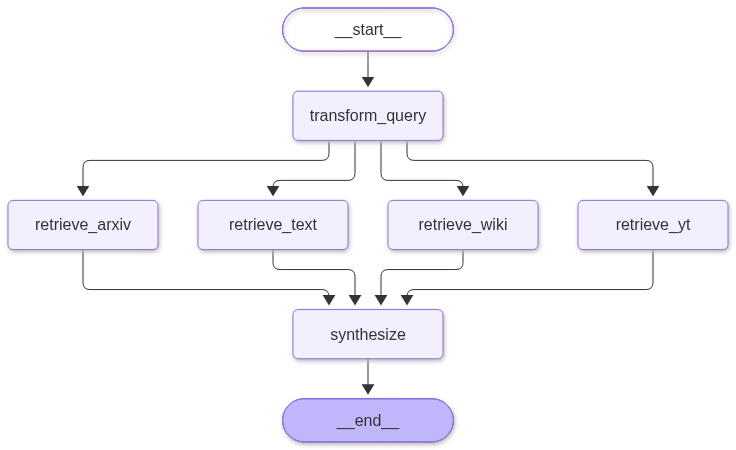

In [21]:
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Diagram render failed (needs internet):", e)

In [22]:
question = "What are transformer agents and how are they evolving in recent research?"
result = graph.invoke(MultiSourceRAGState(question=question))

print("\n✅ Final Answer:\n")
print(result["final_answer"])

🔁 Search query: 'transformer agents recent research evolution'
📄 ArXiv: 'transformer agents recent research evolution'
🌐 Wikipedia: 'transformer agents recent research evolution'

✅ Final Answer:

Transformer agents are AI systems that use transformer‑style neural networks as the core component of an autonomous “agent” – a model that can perceive, reason, and act in an environment, often with memory, feedback loops, and tool‑use capabilities. In recent work, these agents are being extended in several ways:

1. **Architectural and efficiency improvements** – Production deployments now use specialized transformer variants such as EfficientFormer for low‑latency on‑device image classification, Vision Transformers (ViT, Swin) for quality‑control tasks, and Speech Transformers (Wav2Vec 2.0) for voice assistants. Optimizations like FlashAttention and Rotary Positional Encoding have been adopted to speed up inference and improve performance. [INTERNAL]

2. **Agentic capabilities** – Video mat

In [23]:
print("🔁 Search query:", result["search_query"])
print("\n[INTERNAL]", len(result["text_docs"]), "docs")
print("[YOUTUBE] ", len(result["yt_docs"]), "docs")
print("\n[WIKIPEDIA]\n", result["wiki_context"][:500])
print("\n[ARXIV]\n", result["arxiv_context"][:500])

🔁 Search query: transformer agents recent research evolution

[INTERNAL] 3 docs
[YOUTUBE]  1 docs

[WIKIPEDIA]
 Page: Artificial intelligence
Summary: Artificial intelligence (AI) is the capability of computational systems to perform tasks typically associated with human intelligence, such as learning, reasoning, problem-solving, perception, and decision-making. It is also a field of research spanning computer science, engineering, and mathematics that develops and studies methods and software enabling machines to perceive their environment and use learning and intelligence to take actions that maximize t

[ARXIV]
 Published: 2015-12-11
Title: Fixation probability of rare nonmutator and evolution of mutation rates
Authors: Ananthu James, Kavita Jain
Summary: Although mutations drive the evolutionary process, the rates at which the mutations occur are themselves subject to evolutionary forces. Our purpose here is to understand the role of selection and random genetic drift in the evolut